In [ ]:
from google.colab import drive
drive.mount('/content/drive')

Mounted at /content/drive


In [ ]:
import tensorflow as tf
from tensorflow.keras.preprocessing.image import ImageDataGenerator
from tensorflow.keras.applications import VGG16, ResNet50, DenseNet121
from tensorflow.keras.layers import *
from tensorflow.keras.models import Model
from tensorflow.keras.optimizers import Adam
import matplotlib.pyplot as plt
import numpy as np
import cv2
import os

In [ ]:
import zipfile

zip_path = "/content/drive/MyDrive/ChestXRay2017.zip"
extract_path = "/content/extracted_images"

with zipfile.ZipFile(zip_path, 'r') as zip_ref:
    zip_ref.extractall(extract_path)

print(" Extraction completed")

 Extraction completed


In [ ]:
train_dir = "/content/extracted_images/chest_xray/train"


test_dir  = "/content/extracted_images/chest_xray/test"

IMG_SIZE = (224,224)
BATCH_SIZE = 32

In [ ]:
from tensorflow.keras.preprocessing.image import ImageDataGenerator

datagen = ImageDataGenerator(
    rescale=1./255,
    rotation_range=20,
    zoom_range=0.2,
    shear_range=0.1,
    horizontal_flip=True,
    width_shift_range=0.1,
    height_shift_range=0.1,
    validation_split=0.25
)

train_gen = datagen.flow_from_directory(
    train_dir,
    target_size=IMG_SIZE,
    batch_size=BATCH_SIZE,
    class_mode='binary',
    subset='training'
)

val_gen = datagen.flow_from_directory(
    train_dir,
    target_size=IMG_SIZE,
    batch_size=BATCH_SIZE,
    class_mode='binary',
    subset='validation'
)

test_datagen = ImageDataGenerator(rescale=1./255)

test_gen = test_datagen.flow_from_directory(
    test_dir,
    target_size=IMG_SIZE,
    batch_size=1,
    class_mode='binary',
    shuffle=False
)

# -------------------------------
# Print image counts
# -------------------------------
print("\n===== IMAGE COUNTS =====")
print(f"Training Images   : {train_gen.samples}")
print(f"Validation Images : {val_gen.samples}")
print(f"Testing Images    : {test_gen.samples}")

print("\n===== CLASS INDICES =====")
print(train_gen.class_indices)

Found 3925 images belonging to 2 classes.
Found 1307 images belonging to 2 classes.
Found 624 images belonging to 2 classes.

===== IMAGE COUNTS =====
Training Images   : 3925
Validation Images : 1307
Testing Images    : 624

===== CLASS INDICES =====
{'NORMAL': 0, 'PNEUMONIA': 1}


In [ ]:
print(list(train_gen.class_indices.keys()))
print(list(val_gen.class_indices.keys()))
print(list(test_gen.class_indices.keys()))

['NORMAL', 'PNEUMONIA']
['NORMAL', 'PNEUMONIA']
['NORMAL', 'PNEUMONIA']


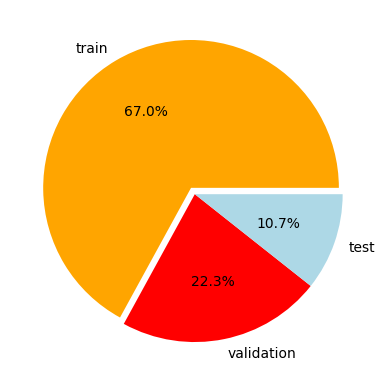

In [ ]:
plt.pie([train_gen.samples, val_gen.samples, test_gen.samples],
        labels=['train', 'validation', 'test'], autopct='%.1f%%', colors=['orange', 'red', 'lightblue'], explode=(0.05, 0, 0))
plt.show()

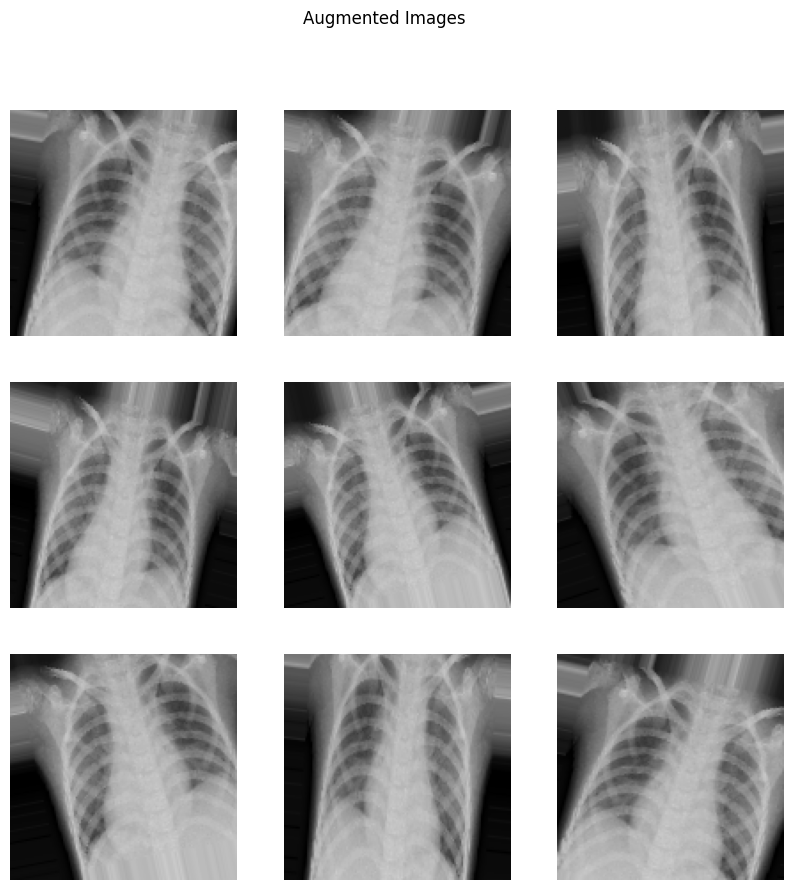

In [ ]:
import matplotlib.pyplot as plt
from tensorflow.keras.preprocessing.image import load_img, img_to_array
import os

# Load one image
normal_images_path = "/content/extracted_images/chest_xray/train/PNEUMONIA"
# Get a list of image files in the NORMAL directory
image_files = [f for f in os.listdir(normal_images_path) if os.path.isfile(os.path.join(normal_images_path, f))]
# Pick the first image file
img_path = os.path.join(normal_images_path, image_files[0])

img = load_img(img_path, target_size=(128,128))
img_array = img_to_array(img)
img_array = img_array.reshape((1,) + img_array.shape)

# Generate augmented images
i = 0
plt.figure(figsize=(10,10))

for batch in datagen.flow(img_array, batch_size=1):
    plt.subplot(3,3,i+1)
    plt.imshow(batch[0])
    plt.axis('off')
    i += 1
    if i == 9:
        break

plt.suptitle("Augmented Images")
plt.show()

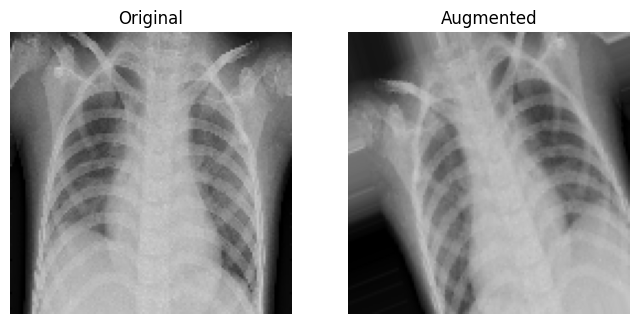

In [ ]:
plt.figure(figsize=(8,4))

# Original image
plt.subplot(1,2,1)
plt.imshow(img)
plt.title("Original")
plt.axis('off')

# Augmented image
aug_img = next(datagen.flow(img_array))[0]

plt.subplot(1,2,2)
plt.imshow(aug_img)
plt.title("Augmented")
plt.axis('off')

plt.show()

In [ ]:
def build_model(base_model):
    x = base_model.output
    x = GlobalAveragePooling2D()(x)
    x = Dense(128, activation='relu')(x)
    x = Dropout(0.5)(x)
    output = Dense(1, activation='sigmoid')(x)

    model = Model(inputs=base_model.input, outputs=output)

    model.compile(
        optimizer=Adam(0.00001),
        loss='binary_crossentropy',
        metrics=['accuracy']
    )
    return model

In [ ]:
base = VGG16(weights='imagenet', include_top=False, input_shape=(224,224,3))
model_vgg = build_model(base)
hist_vgg = model_vgg.fit(train_gen, validation_data=val_gen, epochs=10)

58889256/58889256 ━━━━━━━━━━━━━━━━━━━━ 4s 0us/step
Epoch 1/10
123/123 ━━━━━━━━━━━━━━━━━━━━ 225s 1s/step - accuracy: 0.8561 - loss: 0.3162 - val_accuracy: 0.9342 - val_loss: 0.1819
Epoch 2/10
123/123 ━━━━━━━━━━━━━━━━━━━━ 130s 1s/step - accuracy: 0.9299 - loss: 0.1770 - val_accuracy: 0.9449 - val_loss: 0.1412
Epoch 3/10
123/123 ━━━━━━━━━━━━━━━━━━━━ 128s 1s/step - accuracy: 0.9391 - loss: 0.1574 - val_accuracy: 0.9587 - val_loss: 0.1095
Epoch 4/10
123/123 ━━━━━━━━━━━━━━━━━━━━ 145s 1s/step - accuracy: 0.9506 - loss: 0.1352 - val_accuracy: 0.9679 - val_loss: 0.0904
Epoch 5/10
123/123 ━━━━━━━━━━━━━━━━━━━━ 128s 1s/step - accuracy: 0.9557 - loss: 0.1178 - val_accuracy: 0.9610 - val_loss: 0.1003
Epoch 6/10
123/123 ━━━━━━━━━━━━━━━━━━━━ 129s 1s/step - accuracy: 0.9654 - loss: 0.0925 - val_accuracy: 0.9786 - val_loss: 0.0631
Epoch 7/10
123/123 ━━━━━━━━━━━━━━━━━━━━ 128s 1s/step - accuracy: 0.9684 - loss: 0.0809 - val_accuracy: 0.9725 - val_loss: 0.0641
Epoch 8/10
123/123 ━━━━━━━━━━━━━━━━━━━━ 127s 1

In [ ]:
loss, accuracy = model_vgg.evaluate(test_gen)
print(f"Test Loss: {loss:.4f}")
print(f"Test Accuracy: {accuracy:.2f}")

624/624 ━━━━━━━━━━━━━━━━━━━━ 10s 13ms/step - accuracy: 0.9311 - loss: 0.2101
Test Loss: 0.2101
Test Accuracy: 0.93


In [ ]:
base = ResNet50(weights='imagenet', include_top=False, input_shape=(224,224,3))
model_res = build_model(base)
hist_res = model_res.fit(train_gen, validation_data=val_gen, epochs=10)

94765736/94765736 ━━━━━━━━━━━━━━━━━━━━ 5s 0us/step
Epoch 1/10
123/123 ━━━━━━━━━━━━━━━━━━━━ 218s 1s/step - accuracy: 0.8591 - loss: 0.3163 - val_accuracy: 0.2578 - val_loss: 0.9441
Epoch 2/10
123/123 ━━━━━━━━━━━━━━━━━━━━ 117s 951ms/step - accuracy: 0.9378 - loss: 0.1535 - val_accuracy: 0.7414 - val_loss: 0.5919
Epoch 3/10
123/123 ━━━━━━━━━━━━━━━━━━━━ 116s 942ms/step - accuracy: 0.9529 - loss: 0.1289 - val_accuracy: 0.7422 - val_loss: 0.6476
Epoch 4/10
123/123 ━━━━━━━━━━━━━━━━━━━━ 117s 949ms/step - accuracy: 0.9669 - loss: 0.0932 - val_accuracy: 0.7414 - val_loss: 0.6829
Epoch 5/10
123/123 ━━━━━━━━━━━━━━━━━━━━ 117s 945ms/step - accuracy: 0.9732 - loss: 0.0742 - val_accuracy: 0.7422 - val_loss: 0.9336
Epoch 6/10
123/123 ━━━━━━━━━━━━━━━━━━━━ 119s 962ms/step - accuracy: 0.9727 - loss: 0.0708 - val_accuracy: 0.7422 - val_loss: 1.3103
Epoch 7/10
123/123 ━━━━━━━━━━━━━━━━━━━━ 117s 949ms/step - accuracy: 0.9773 - loss: 0.0569 - val_accuracy: 0.7422 - val_loss: 1.3535
Epoch 8/10
123/123 ━━━━━━━━━

In [ ]:
loss, accuracy = model_res.evaluate(test_gen)
print(f"Test Loss: {loss:.4f}")
print(f"Test Accuracy: {accuracy:.2f}")

624/624 ━━━━━━━━━━━━━━━━━━━━ 13s 16ms/step - accuracy: 0.7580 - loss: 0.6843
Test Loss: 0.6843
Test Accuracy: 0.76


In [ ]:
from tensorflow.keras.applications import DenseNet121
base = DenseNet121(weights='imagenet', include_top=False, input_shape=(224,224,3))
model_dense = build_model(base)
hist_dense = model_dense.fit(train_gen, validation_data=val_gen, epochs=10)

29084464/29084464 ━━━━━━━━━━━━━━━━━━━━ 2s 0us/step
Epoch 1/10
123/123 ━━━━━━━━━━━━━━━━━━━━ 464s 2s/step - accuracy: 0.8041 - loss: 0.4296 - val_accuracy: 0.7460 - val_loss: 0.4879
Epoch 2/10
123/123 ━━━━━━━━━━━━━━━━━━━━ 117s 951ms/step - accuracy: 0.9146 - loss: 0.2228 - val_accuracy: 0.7437 - val_loss: 0.6007
Epoch 3/10
123/123 ━━━━━━━━━━━━━━━━━━━━ 117s 950ms/step - accuracy: 0.9406 - loss: 0.1592 - val_accuracy: 0.7536 - val_loss: 0.6051
Epoch 4/10
123/123 ━━━━━━━━━━━━━━━━━━━━ 118s 956ms/step - accuracy: 0.9590 - loss: 0.1246 - val_accuracy: 0.8447 - val_loss: 0.3028
Epoch 5/10
123/123 ━━━━━━━━━━━━━━━━━━━━ 117s 955ms/step - accuracy: 0.9587 - loss: 0.1164 - val_accuracy: 0.8638 - val_loss: 0.2884
Epoch 6/10
123/123 ━━━━━━━━━━━━━━━━━━━━ 117s 955ms/step - accuracy: 0.9679 - loss: 0.0974 - val_accuracy: 0.9717 - val_loss: 0.0792
Epoch 7/10
123/123 ━━━━━━━━━━━━━━━━━━━━ 118s 958ms/step - accuracy: 0.9732 - loss: 0.0789 - val_accuracy: 0.9809 - val_loss: 0.0547
Epoch 8/10
123/123 ━━━━━━━━━

In [ ]:
print("VGG16:", model_vgg.evaluate(test_gen))
print("ResNet50:", model_res.evaluate(test_gen))
print("DenseNet121:", model_dense.evaluate(test_gen))



624/624 ━━━━━━━━━━━━━━━━━━━━ 9s 14ms/step - accuracy: 0.9311 - loss: 0.2101
VGG16: [0.21014359593391418, 0.9310897588729858]
624/624 ━━━━━━━━━━━━━━━━━━━━ 8s 13ms/step - accuracy: 0.7580 - loss: 0.6843
ResNet50: [0.684288501739502, 0.7580128312110901]
624/624 ━━━━━━━━━━━━━━━━━━━━ 22s 20ms/step - accuracy: 0.8798 - loss: 0.3211
DenseNet121: [0.32110175490379333, 0.879807710647583]


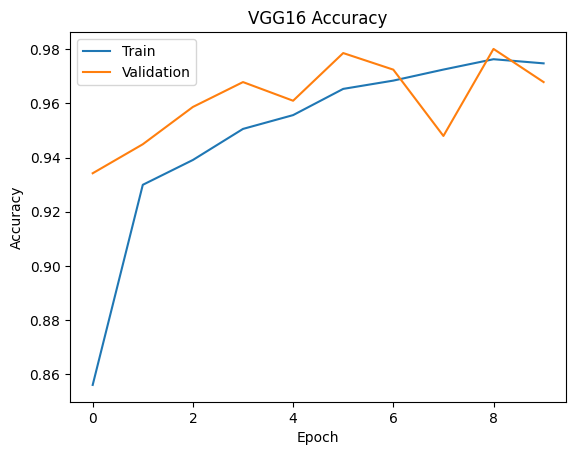

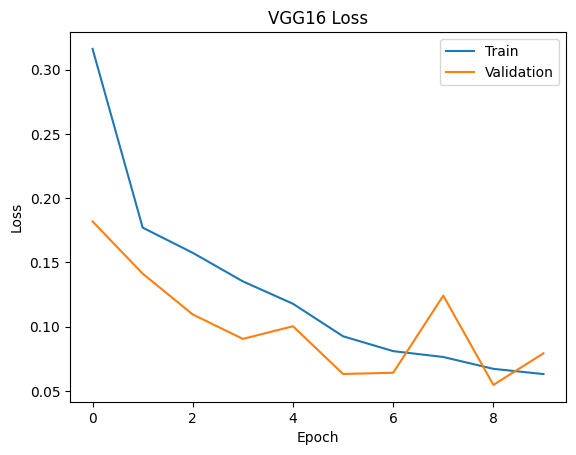

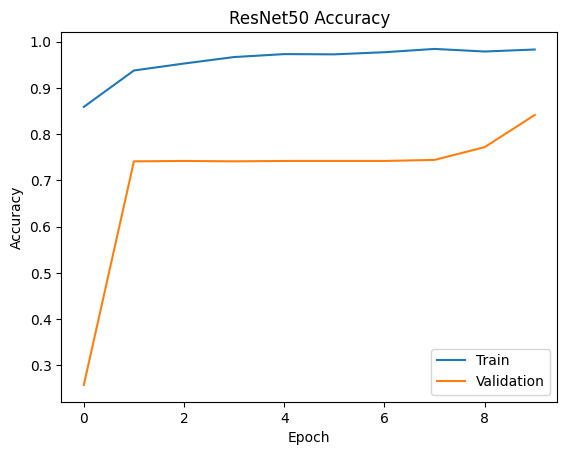

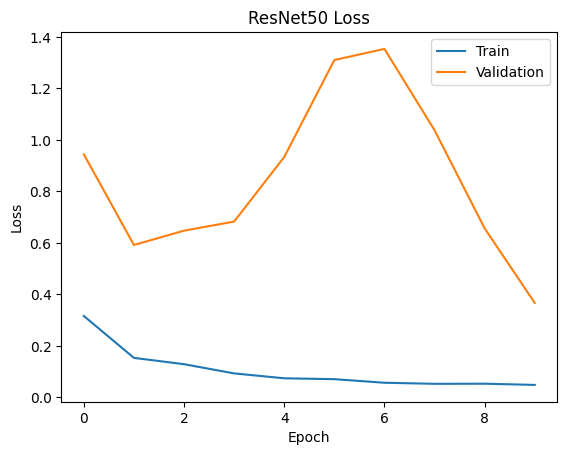

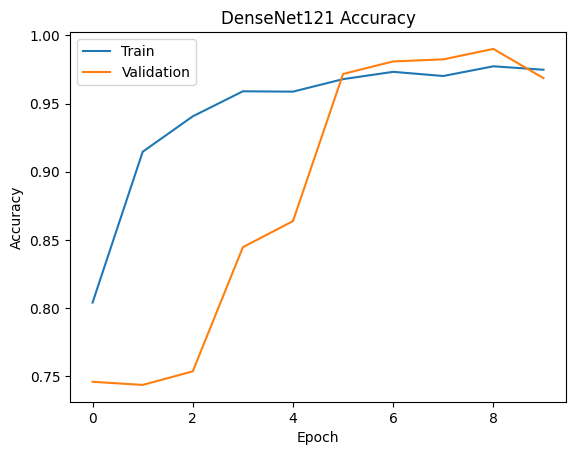

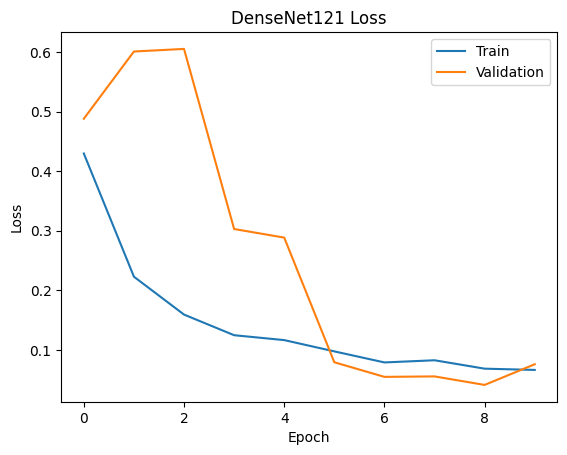

In [ ]:
import matplotlib.pyplot as plt

histories = {
    'VGG16': hist_vgg,
    'ResNet50': hist_res,
    'DenseNet121': hist_dense


}

for name, history in histories.items():

    # Accuracy Plot
    plt.figure()
    plt.plot(history.history['accuracy'])
    plt.plot(history.history['val_accuracy'])
    plt.title(f'{name} Accuracy')
    plt.xlabel('Epoch')
    plt.ylabel('Accuracy')
    plt.legend(['Train', 'Validation'])
    plt.show()

    # Loss Plot
    plt.figure()
    plt.plot(history.history['loss'])
    plt.plot(history.history['val_loss'])
    plt.title(f'{name} Loss')
    plt.xlabel('Epoch')
    plt.ylabel('Loss')
    plt.legend(['Train', 'Validation'])
    plt.show()

In [ ]:
from sklearn.metrics import classification_report, confusion_matrix, accuracy_score
import numpy as np
import seaborn as sns
import matplotlib.pyplot as plt

In [ ]:
all_predictions = {}
all_true = test_gen.classes   # True labels

models = {
    'VGG16': model_vgg,
    'ResNet50': model_res,
    'DenseNet121': model_dense


}

for name, model in models.items():
    print(f"\nEvaluating {name}...")

    preds = model.predict(test_gen)
    preds = (preds > 0.5).astype(int).reshape(-1)

    all_predictions[name] = preds


Evaluating VGG16...
624/624 ━━━━━━━━━━━━━━━━━━━━ 9s 13ms/step

Evaluating ResNet50...
624/624 ━━━━━━━━━━━━━━━━━━━━ 14s 15ms/step

Evaluating DenseNet121...
624/624 ━━━━━━━━━━━━━━━━━━━━ 22s 19ms/step


In [ ]:
for name, preds in all_predictions.items():
    print(f"\n {name} Classification Report:")

    print(classification_report(all_true, preds, target_names=["Normal", "Pneumonia"]))


 VGG16 Classification Report:
              precision    recall  f1-score   support

      Normal       0.92      0.89      0.91       234
   Pneumonia       0.94      0.95      0.95       390

    accuracy                           0.93       624
   macro avg       0.93      0.92      0.93       624
weighted avg       0.93      0.93      0.93       624


 ResNet50 Classification Report:
              precision    recall  f1-score   support

      Normal       0.98      0.36      0.53       234
   Pneumonia       0.72      0.99      0.84       390

    accuracy                           0.76       624
   macro avg       0.85      0.68      0.68       624
weighted avg       0.82      0.76      0.72       624


 DenseNet121 Classification Report:
              precision    recall  f1-score   support

      Normal       0.78      0.95      0.86       234
   Pneumonia       0.96      0.84      0.90       390

    accuracy                           0.88       624
   macro avg       0.87   

In [ ]:
def plot_confusion_matrix(y_true, y_pred, model_name):
    cm = confusion_matrix(y_true, y_pred)

    plt.figure()
    sns.heatmap(cm, annot=True, fmt='d', cmap='Blues')

    plt.title(f"{model_name} Confusion Matrix")
    plt.xlabel("Predicted")
    plt.ylabel("Actual")

    plt.show()

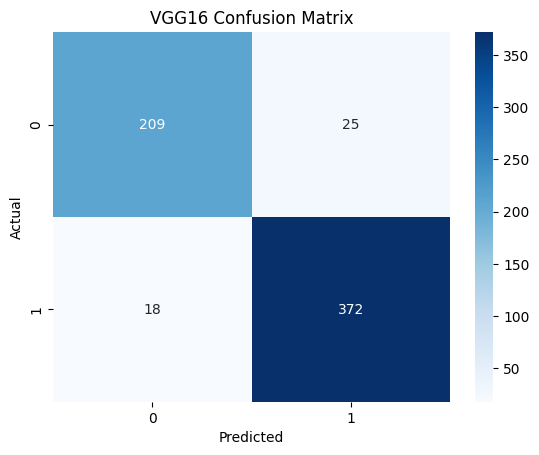

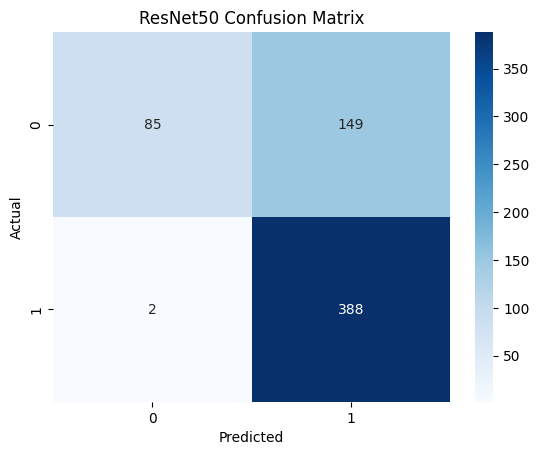

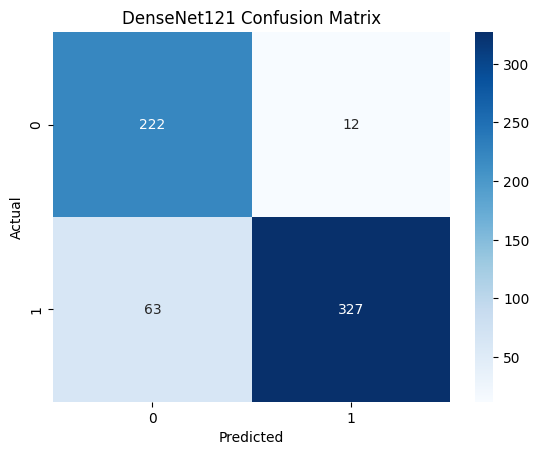

In [ ]:
for name, preds in all_predictions.items():
    plot_confusion_matrix(all_true, preds, name)

In [ ]:
accuracies = {}

for name, preds in all_predictions.items():
    acc = accuracy_score(all_true, preds)
    accuracies[name] = acc
    print(f"{name} Accuracy: {acc:.4f}")

VGG16 Accuracy: 0.9311
ResNet50 Accuracy: 0.7580
DenseNet121 Accuracy: 0.8798



Processing VGG16...
624/624 ━━━━━━━━━━━━━━━━━━━━ 7s 11ms/step

Processing ResNet50...
624/624 ━━━━━━━━━━━━━━━━━━━━ 8s 13ms/step

Processing DenseNet121...
624/624 ━━━━━━━━━━━━━━━━━━━━ 12s 19ms/step


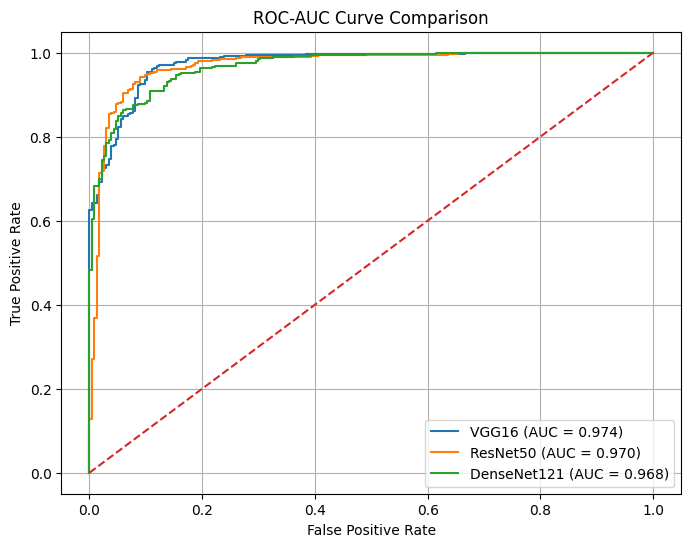

In [ ]:
import matplotlib.pyplot as plt
from sklearn.metrics import roc_curve, auc

all_probs = {}   # store probabilities
y_true = test_gen.classes   # true labels

models = {
    'VGG16': model_vgg,
    'ResNet50': model_res,
    'DenseNet121': model_dense



}

#  Get probabilities (NOT thresholded)
for name, model in models.items():
    print(f"\nProcessing {name}...")

    probs = model.predict(test_gen)
    probs = probs.ravel()   # flatten

    all_probs[name] = probs


#  Plot ROC curves
plt.figure(figsize=(8,6))

for name, probs in all_probs.items():
    fpr, tpr, _ = roc_curve(y_true, probs)
    roc_auc = auc(fpr, tpr)

    plt.plot(fpr, tpr, label=f'{name} (AUC = {roc_auc:.3f})')

# Random line
plt.plot([0,1], [0,1], linestyle='--')

plt.xlabel('False Positive Rate')
plt.ylabel('True Positive Rate')
plt.title('ROC-AUC Curve Comparison')
plt.legend(loc='lower right')
plt.grid()

plt.show()

In [ ]:
best_model_name = max(accuracies, key=accuracies.get)
print("Best Model:", best_model_name)

best_model = models[best_model_name]

Best Model: VGG16


SINGLE MODEL PREDICTION

In [ ]:
import numpy as np
import tensorflow as tf
from tensorflow.keras.preprocessing import image
import matplotlib.pyplot as plt

def predict_image(img_path, model):
    # Load image
    img = image.load_img(img_path, target_size=(224, 224))

    # Convert to array
    img_array = image.img_to_array(img)
    img_array = img_array / 255.0   # normalization
    img_array = np.expand_dims(img_array, axis=0)

    # Prediction
    prediction = model.predict(img_array)[0][0]

    # Class label
    if prediction > 0.5:
        label = "PNEUMONIA"
        confidence = prediction
    else:
        label = "NORMAL"
        confidence = 1 - prediction

    # Show image
    plt.imshow(img)
    plt.title(f"Prediction: {label} ({confidence:.2f})")
    plt.axis("off")
    plt.show()

    print(f"Prediction: {label}")
    print(f"Confidence: {confidence:.4f}")

1/1 ━━━━━━━━━━━━━━━━━━━━ 1s 665ms/step


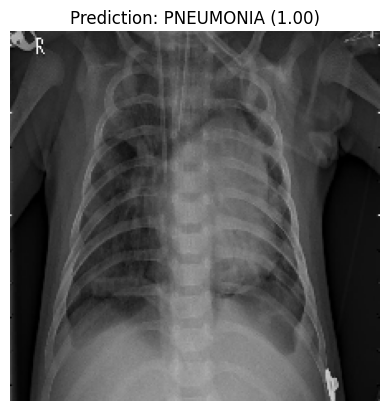

Prediction: PNEUMONIA
Confidence: 0.9961


In [ ]:
predict_image("/content/extracted_images/chest_xray/test/PNEUMONIA/person100_bacteria_477.jpeg", best_model)

1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 50ms/step


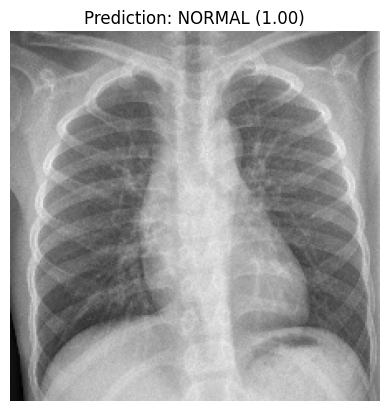

Prediction: NORMAL
Confidence: 0.9956


In [ ]:
predict_image("/content/extracted_images/chest_xray/test/NORMAL/IM-0006-0001.jpeg", best_model)

In [ ]:
import tensorflow as tf
from tensorflow.keras.applications import VGG16
from tensorflow.keras.layers import Input, Conv2D, Flatten, Dense, Layer
from tensorflow.keras.models import Model

#  Custom MAM Pooling Layer (TensorFlow version)
class MAMPooling(Layer):
    def __init__(self, pool_size=2, strides=2):
        super(MAMPooling, self).__init__()
        self.pool_size = pool_size
        self.strides = strides

    def call(self, inputs):
        # Max, Min, Avg
        max_pool = tf.nn.max_pool2d(inputs, ksize=self.pool_size, strides=self.strides, padding='VALID')
        min_pool = -tf.nn.max_pool2d(-inputs, ksize=self.pool_size, strides=self.strides, padding='VALID')
        avg_pool = tf.nn.avg_pool2d(inputs, ksize=self.pool_size, strides=self.strides, padding='VALID')

        diff = max_pool - min_pool

        # Condition: if diff > avg → diff else (max+min)/2
        condition = tf.greater(diff, avg_pool)

        mam = tf.where(condition, diff, (max_pool + min_pool) / 2)

        return mam

In [ ]:
import tensorflow as tf
from tensorflow.keras.applications import VGG16
from tensorflow.keras.layers import Input, Conv2D, Flatten, Dense, Layer, BatchNormalization, Dropout, GlobalAveragePooling2D
from tensorflow.keras.models import Model
from tensorflow.keras.optimizers import Adam

# Custom MAM Pooling Layer (TensorFlow version) - assuming this is defined elsewhere or in an earlier cell
# If not, it needs to be included here or imported.
# For the purpose of this fix, I'm assuming it's available.
class MAMPooling(Layer):
    def __init__(self, pool_size=2, strides=2):
        super(MAMPooling, self).__init__()
        self.pool_size = pool_size
        self.strides = strides

    def call(self, inputs):
        # Max, Min, Avg
        max_pool = tf.nn.max_pool2d(inputs, ksize=self.pool_size, strides=self.strides, padding='VALID')
        min_pool = -tf.nn.max_pool2d(-inputs, ksize=self.pool_size, strides=self.strides, padding='VALID')
        avg_pool = tf.nn.avg_pool2d(inputs, ksize=self.pool_size, strides=self.strides, padding='VALID')

        diff = max_pool - min_pool

        # Condition: if diff > avg → diff else (max+min)/2
        condition = tf.greater(diff, avg_pool)

        mam = tf.where(condition, diff, (max_pool + min_pool) / 2)

        return mam



#  Base VGG16
base_model = VGG16(weights='imagenet', include_top=False, input_tensor=Input(shape=(224,224,3)))

x = base_model.output # Output shape: (None, 7, 7, 512) for 224x224 input



# Block 2: Reduces 3x3 to 1x1
x = Conv2D(128, (3,3), activation='relu', padding='same')(x)
x = BatchNormalization()(x)
x = MAMPooling(pool_size=2, strides=2)(x) # Shape: (None, 1, 1, 128)



x = Conv2D(128, (3,3), activation='relu', padding='same')(x) # Shape: (None, 1, 1, 128)
x = BatchNormalization()(x)

#  Apply Global Average Pooling (as the feature map is already 1x1)
x = GlobalAveragePooling2D()(x) # Shape: (None, 128)

# Flatten is redundant after GlobalAveragePooling2D, as GAP2D outputs a 1D tensor.
# x = Flatten()(x)

# Output Layer
x = Dense(128, activation='relu')(x)
x = Dropout(0.5)(x)
x = Dense(1, activation='sigmoid')(x)

# Final Model
model_mam_conv = Model(inputs=base_model.input, outputs=x)

# Compile
model_mam_conv.compile(
    optimizer=Adam(0.00001),
    loss='binary_crossentropy',
    metrics=['accuracy']
)

# Summary
model_mam_conv.summary()

Model: "functional_4"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ input_layer_4 (InputLayer)      │ (None, 224, 224, 3)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ block1_conv1 (Conv2D)           │ (None, 224, 224, 64)   │         1,792 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ block1_conv2 (Conv2D)           │ (None, 224, 224, 64)   │        36,928 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ block1_pool (MaxPooling2D)      │ (None, 112, 112, 64)   │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ block2_conv1 (Conv2D)           │ (None, 112, 112, 128)  │        73,856 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ block2_conv2 (Conv2D)           │ (None, 112, 112, 128)  │       147,584 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ block2_pool (MaxPooling2D)      │ (None, 56, 56, 128)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ block3_conv1 (Conv2D)           │ (None, 56, 56, 256)    │       295,168 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ block3_conv2 (Conv2D)           │ (None, 56, 56, 256)    │       590,080 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ block3_conv3 (Conv2D)           │ (None, 56, 56, 256)    │       590,080 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ block3_pool (MaxPooling2D)      │ (None, 28, 28, 256)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ block4_conv1 (Conv2D)           │ (None, 28, 28, 512)    │     1,180,160 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ block4_conv2 (Conv2D)           │ (None, 28, 28, 512)    │     2,359,808 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ block4_conv3 (Conv2D)           │ (None, 28, 28, 512)    │     2,359,808 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ block4_pool (MaxPooling2D)      │ (None, 14, 14, 512)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ block5_conv1 (Conv2D)           │ (None, 14, 14, 512)    │     2,359,808 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ block5_conv2 (Conv2D)           │ (None, 14, 14, 512)    │     2,359,808 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ block5_conv3 (Conv2D)           │ (None, 14, 14, 512)    │     2,359,808 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ block5_pool (MaxPooling2D)      │ (None, 7, 7, 512)      │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_2 (Conv2D)               │ (None, 7, 7, 128)      │       589,952 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_normalization_2           │ (None, 7, 7, 128)      │           512 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ mam_pooling_1 (MAMPooling)      │ (None, 3, 3, 128)      │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_3 (Conv2D)               │ (None, 3, 3, 128)      │       147,584 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_normalization_3           │ (None, 3, 3, 128)      │           512 │
│ (BatchNormalization)            │                        │             

 Total params: 15,469,889 (59.01 MB)

 Trainable params: 15,469,377 (59.01 MB)

 Non-trainable params: 512 (2.00 KB)

In [ ]:
# Train Model BEFORE Flatten
history_before = model_mam_conv.fit(
    train_gen,
    validation_data=val_gen,
    epochs=10
)

Epoch 1/10
123/123 ━━━━━━━━━━━━━━━━━━━━ 148s 1s/step - accuracy: 0.8418 - loss: 0.4350 - val_accuracy: 0.8998 - val_loss: 0.5355
Epoch 2/10
123/123 ━━━━━━━━━━━━━━━━━━━━ 129s 1s/step - accuracy: 0.9225 - loss: 0.2636 - val_accuracy: 0.9350 - val_loss: 0.3136
Epoch 3/10
123/123 ━━━━━━━━━━━━━━━━━━━━ 129s 1s/step - accuracy: 0.9358 - loss: 0.2057 - val_accuracy: 0.9380 - val_loss: 0.2152
Epoch 4/10
123/123 ━━━━━━━━━━━━━━━━━━━━ 129s 1s/step - accuracy: 0.9541 - loss: 0.1643 - val_accuracy: 0.9464 - val_loss: 0.1702
Epoch 5/10
123/123 ━━━━━━━━━━━━━━━━━━━━ 129s 1s/step - accuracy: 0.9592 - loss: 0.1341 - val_accuracy: 0.9740 - val_loss: 0.0928
Epoch 6/10
123/123 ━━━━━━━━━━━━━━━━━━━━ 130s 1s/step - accuracy: 0.9615 - loss: 0.1261 - val_accuracy: 0.9579 - val_loss: 0.1093
Epoch 7/10
123/123 ━━━━━━━━━━━━━━━━━━━━ 130s 1s/step - accuracy: 0.9712 - loss: 0.0968 - val_accuracy: 0.9801 - val_loss: 0.0780
Epoch 8/10
123/123 ━━━━━━━━━━━━━━━━━━━━ 141s 1s/step - accuracy: 0.9699 - loss: 0.1030 - val_accu

In [ ]:
loss,acc = model_mam_conv.evaluate(test_gen)
print(f"Test Loss: {loss:.4f}")
print(f"Test Accuracy: {acc:.2f}")

624/624 ━━━━━━━━━━━━━━━━━━━━ 10s 14ms/step - accuracy: 0.9215 - loss: 0.2279
Test Loss: 0.2279
Test Accuracy: 0.92


In [ ]:


#  Load VGG16
base_model = VGG16(weights='imagenet', include_top=False, input_tensor=Input(shape=(224,224,3)))

x = base_model.output

#  Apply MAM Pooling BEFORE flatten
x = MAMPooling(pool_size=2, strides=2)(x)

# Flatten
x = GlobalAveragePooling2D()(x)

#  3 Increasing Dense Layers
x = Dense(128, activation='relu')(x)
x = Dropout(0.5)(x)
x = Dense(256, activation='relu')(x)
x = Dropout(0.3)(x)
x = Dense(512, activation='relu')(x)

# Output Layer
x = Dense(1, activation='sigmoid')(x)

# Final Model
model_final = Model(inputs=base_model.input, outputs=x)

# Compile
model_final.compile(
    optimizer=Adam(0.00001),
    loss='binary_crossentropy',
    metrics=['accuracy']
)

# Summary
model_final.summary()

Model: "functional_8"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ input_layer_8 (InputLayer)      │ (None, 224, 224, 3)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ block1_conv1 (Conv2D)           │ (None, 224, 224, 64)   │         1,792 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ block1_conv2 (Conv2D)           │ (None, 224, 224, 64)   │        36,928 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ block1_pool (MaxPooling2D)      │ (None, 112, 112, 64)   │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ block2_conv1 (Conv2D)           │ (None, 112, 112, 128)  │        73,856 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ block2_conv2 (Conv2D)           │ (None, 112, 112, 128)  │       147,584 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ block2_pool (MaxPooling2D)      │ (None, 56, 56, 128)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ block3_conv1 (Conv2D)           │ (None, 56, 56, 256)    │       295,168 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ block3_conv2 (Conv2D)           │ (None, 56, 56, 256)    │       590,080 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ block3_conv3 (Conv2D)           │ (None, 56, 56, 256)    │       590,080 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ block3_pool (MaxPooling2D)      │ (None, 28, 28, 256)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ block4_conv1 (Conv2D)           │ (None, 28, 28, 512)    │     1,180,160 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ block4_conv2 (Conv2D)           │ (None, 28, 28, 512)    │     2,359,808 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ block4_conv3 (Conv2D)           │ (None, 28, 28, 512)    │     2,359,808 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ block4_pool (MaxPooling2D)      │ (None, 14, 14, 512)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ block5_conv1 (Conv2D)           │ (None, 14, 14, 512)    │     2,359,808 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ block5_conv2 (Conv2D)           │ (None, 14, 14, 512)    │     2,359,808 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ block5_conv3 (Conv2D)           │ (None, 14, 14, 512)    │     2,359,808 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ block5_pool (MaxPooling2D)      │ (None, 7, 7, 512)      │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ mam_pooling_3 (MAMPooling)      │ (None, 3, 3, 512)      │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ global_average_pooling2d_5      │ (None, 512)            │             0 │
│ (GlobalAveragePooling2D)        │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_20 (Dense)                │ (None, 128)            │        65,664 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_6 (Dropout)             │ (None, 128)            │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_21 (Dense)                │ (None, 256)            │        33,024 │
├─────────────────────────────────┼────────────────────────┼─────────────

 Total params: 14,945,473 (57.01 MB)

 Trainable params: 14,945,473 (57.01 MB)

 Non-trainable params: 0 (0.00 B)

In [ ]:


# Train Model AFTER Flatten
history_after = model_final.fit(
    train_gen,
    validation_data=val_gen,
    epochs=10
)

Epoch 1/10
131/131 ━━━━━━━━━━━━━━━━━━━━ 155s 1s/step - accuracy: 0.8078 - loss: 0.3861 - val_accuracy: 0.9118 - val_loss: 0.1996
Epoch 2/10
131/131 ━━━━━━━━━━━━━━━━━━━━ 144s 1s/step - accuracy: 0.9128 - loss: 0.2291 - val_accuracy: 0.9252 - val_loss: 0.1740
Epoch 3/10
131/131 ━━━━━━━━━━━━━━━━━━━━ 138s 1s/step - accuracy: 0.9415 - loss: 0.1684 - val_accuracy: 0.9463 - val_loss: 0.1390
Epoch 4/10
131/131 ━━━━━━━━━━━━━━━━━━━━ 140s 1s/step - accuracy: 0.9456 - loss: 0.1514 - val_accuracy: 0.9597 - val_loss: 0.1118
Epoch 5/10
131/131 ━━━━━━━━━━━━━━━━━━━━ 138s 1s/step - accuracy: 0.9499 - loss: 0.1441 - val_accuracy: 0.9166 - val_loss: 0.1939
Epoch 6/10
131/131 ━━━━━━━━━━━━━━━━━━━━ 139s 1s/step - accuracy: 0.9583 - loss: 0.1196 - val_accuracy: 0.9655 - val_loss: 0.0857
Epoch 7/10
131/131 ━━━━━━━━━━━━━━━━━━━━ 144s 1s/step - accuracy: 0.9538 - loss: 0.1278 - val_accuracy: 0.9492 - val_loss: 0.1282
Epoch 8/10
131/131 ━━━━━━━━━━━━━━━━━━━━ 145s 1s/step - accuracy: 0.9681 - loss: 0.0977 - val_accu

In [ ]:
import tensorflow as tf

# Evaluate Model BEFORE Flatten
print(" Evaluating Model BEFORE Flatten...")
loss_before, acc_before = model_mam_conv.evaluate(test_gen)

# Evaluate Model AFTER Flatten
print("\n Evaluating Model AFTER Flatten...")
loss_after, acc_after = model_final.evaluate(test_gen)

 Evaluating Model BEFORE Flatten...
624/624 ━━━━━━━━━━━━━━━━━━━━ 9s 15ms/step - accuracy: 0.9215 - loss: 0.2279

 Evaluating Model AFTER Flatten...
624/624 ━━━━━━━━━━━━━━━━━━━━ 8s 12ms/step - accuracy: 0.9375 - loss: 0.1777


In [ ]:
print("\n FINAL COMPARISON:")
print(f"Before Flatten → Loss: {loss_before:.4f}, Accuracy: {acc_before:.4f}")
print(f"After Flatten  → Loss: {loss_after:.4f}, Accuracy: {acc_after:.4f}")


 FINAL COMPARISON:
Before Flatten → Loss: 0.2279, Accuracy: 0.9215
After Flatten  → Loss: 0.1777, Accuracy: 0.9375


In [ ]:
from sklearn.metrics import classification_report, confusion_matrix
import numpy as np

# True labels
y_true = test_gen.classes

# Predictions (Before)
y_pred_before = model_mam_conv.predict(test_gen)
y_pred_before = (y_pred_before > 0.5).astype(int).reshape(-1)

# Predictions (After)
y_pred_after = model_final.predict(test_gen)
y_pred_after = (y_pred_after > 0.5).astype(int).reshape(-1)

#  BEFORE Flatten
print("\n BEFORE Flatten - Classification Report")
print(classification_report(y_true, y_pred_before))

print("Confusion Matrix:")
print(confusion_matrix(y_true, y_pred_before))


#  AFTER Flatten
print("\n AFTER Flatten - Classification Report")
print(classification_report(y_true, y_pred_after))

print("Confusion Matrix:")
print(confusion_matrix(y_true, y_pred_after))

624/624 ━━━━━━━━━━━━━━━━━━━━ 9s 13ms/step
624/624 ━━━━━━━━━━━━━━━━━━━━ 10s 15ms/step

 BEFORE Flatten - Classification Report
              precision    recall  f1-score   support

           0       0.91      0.87      0.89       234
           1       0.93      0.95      0.94       390

    accuracy                           0.92       624
   macro avg       0.92      0.91      0.92       624
weighted avg       0.92      0.92      0.92       624

Confusion Matrix:
[[204  30]
 [ 19 371]]

 AFTER Flatten - Classification Report
              precision    recall  f1-score   support

           0       0.95      0.88      0.91       234
           1       0.93      0.97      0.95       390

    accuracy                           0.94       624
   macro avg       0.94      0.93      0.93       624
weighted avg       0.94      0.94      0.94       624

Confusion Matrix:
[[207  27]
 [ 12 378]]


In [ ]:
test_gen.reset()

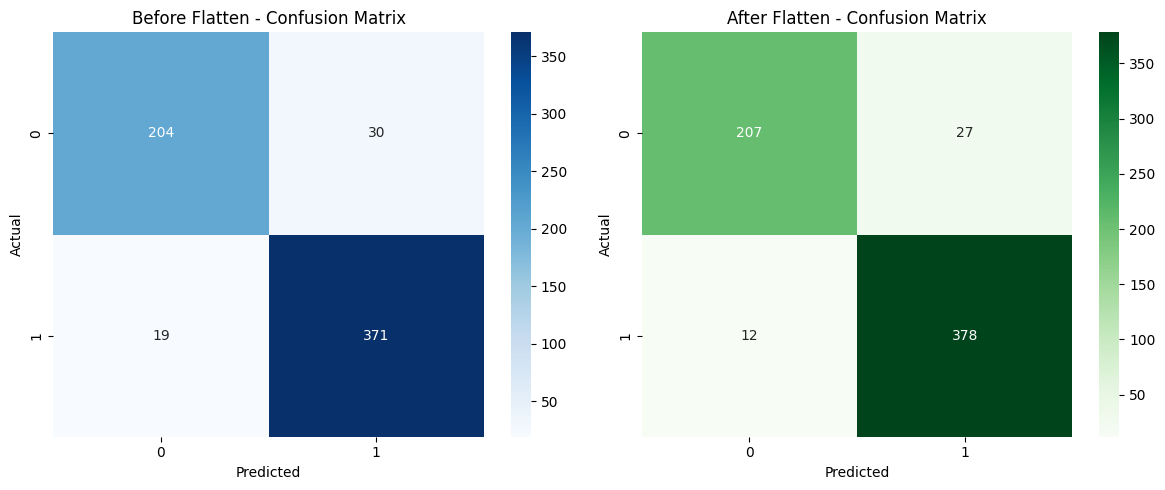

In [ ]:
# Confusion matrices
cm_before = confusion_matrix(y_true, y_pred_before)
cm_after = confusion_matrix(y_true, y_pred_after)

#  Plot side by side
plt.figure(figsize=(12,5))

# BEFORE Flatten
plt.subplot(1,2,1)
sns.heatmap(cm_before, annot=True, fmt='d', cmap='Blues')
plt.title('Before Flatten - Confusion Matrix')
plt.xlabel('Predicted')
plt.ylabel('Actual')

# AFTER Flatten
plt.subplot(1,2,2)
sns.heatmap(cm_after, annot=True, fmt='d', cmap='Greens')
plt.title('After Flatten - Confusion Matrix')
plt.xlabel('Predicted')
plt.ylabel('Actual')

plt.tight_layout()
plt.show()

624/624 ━━━━━━━━━━━━━━━━━━━━ 11s 17ms/step
624/624 ━━━━━━━━━━━━━━━━━━━━ 7s 12ms/step


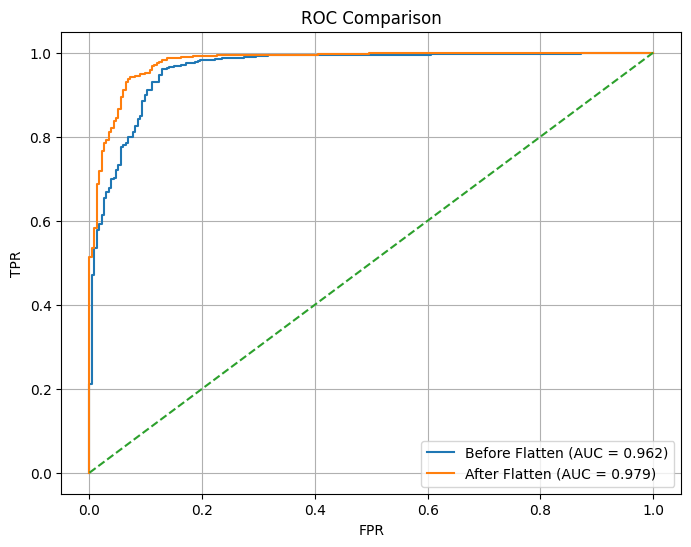

In [ ]:
from sklearn.metrics import roc_curve, auc
import matplotlib.pyplot as plt

test_gen.reset()

# Probabilities (NOT thresholded)
y_prob_before = model_mam_conv.predict(test_gen).ravel()
y_prob_after = model_final.predict(test_gen).ravel()

y_true = test_gen.classes

# ROC
fpr_b, tpr_b, _ = roc_curve(y_true, y_prob_before)
auc_b = auc(fpr_b, tpr_b)

fpr_a, tpr_a, _ = roc_curve(y_true, y_prob_after)
auc_a = auc(fpr_a, tpr_a)

# Plot
plt.figure(figsize=(8,6))
plt.plot(fpr_b, tpr_b, label=f'Before Flatten (AUC = {auc_b:.3f})')
plt.plot(fpr_a, tpr_a, label=f'After Flatten (AUC = {auc_a:.3f})')
plt.plot([0,1], [0,1], linestyle='--')

plt.xlabel("FPR")
plt.ylabel("TPR")
plt.title("ROC Comparison")
plt.legend()
plt.grid()
plt.show()

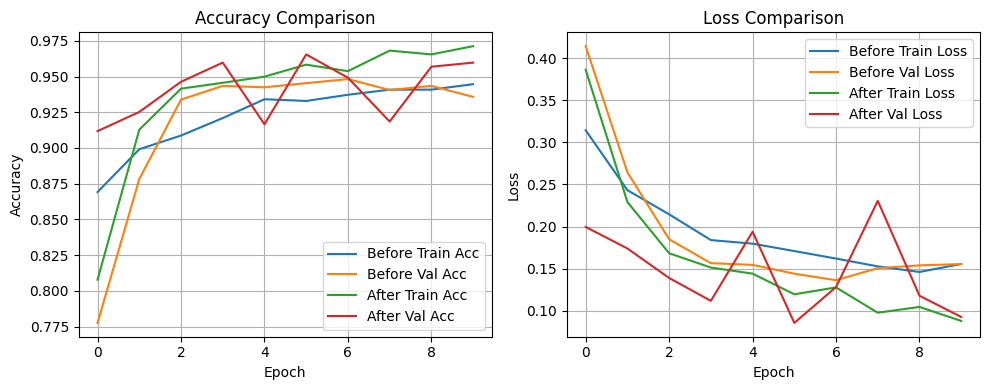

In [ ]:
import matplotlib.pyplot as plt

#  Accuracy Plot
plt.figure(figsize=(10,4))

plt.subplot(1,2,1)
plt.plot(history_before.history['accuracy'], label='Before Train Acc')
plt.plot(history_before.history['val_accuracy'], label='Before Val Acc')

plt.plot(history_after.history['accuracy'], label='After Train Acc')
plt.plot(history_after.history['val_accuracy'], label='After Val Acc')

plt.title('Accuracy Comparison')
plt.xlabel('Epoch')
plt.ylabel('Accuracy')
plt.legend()
plt.grid()

#  Loss Plot
plt.subplot(1,2,2)
plt.plot(history_before.history['loss'], label='Before Train Loss')
plt.plot(history_before.history['val_loss'], label='Before Val Loss')

plt.plot(history_after.history['loss'], label='After Train Loss')
plt.plot(history_after.history['val_loss'], label='After Val Loss')

plt.title('Loss Comparison')
plt.xlabel('Epoch')
plt.ylabel('Loss')
plt.legend()
plt.grid()

plt.tight_layout()
plt.show()

In [ ]:
#  Store accuracies properly
accuracies = {
    "Before Flatten": acc_before,
    "After Flatten": acc_after
}

#  Store models
models = {
    "Before Flatten": model_mam_conv,
    "After Flatten": model_final
}

#  Select best model
best_model_name = max(accuracies, key=accuracies.get)
best_model = models[best_model_name]

print(" Best Model:", best_model_name)

 Best Model: After Flatten


In [ ]:
best_model.save("VGG16_after_flatten_best.keras")
print("Model saved succesfully")

Model saved succesfully


/usr/local/lib/python3.12/dist-packages/keras/src/models/functional.py:241: UserWarning: The structure of `inputs` doesn't match the expected structure.
Expected: [['keras_tensor_1211']]
Received: inputs=Tensor(shape=(1, 224, 224, 3))
  warnings.warn(msg)


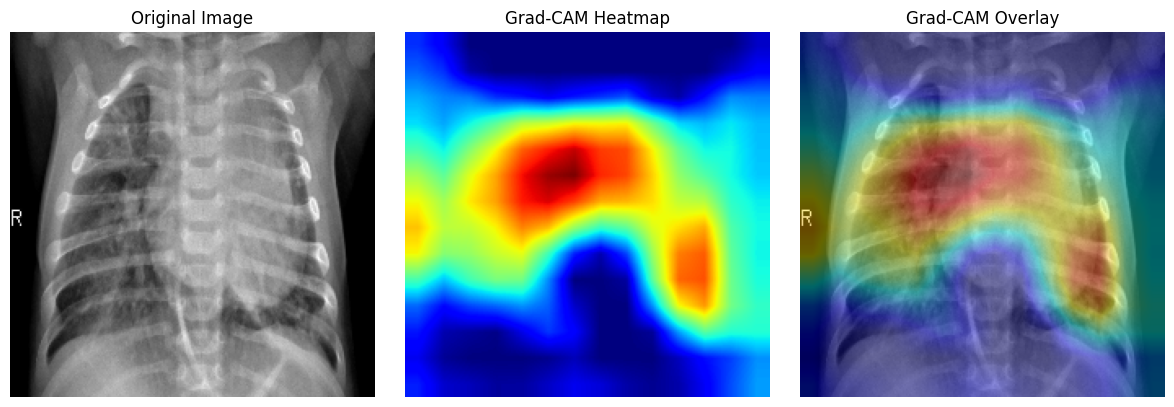

In [ ]:
import tensorflow as tf
import numpy as np
import cv2
import matplotlib.pyplot as plt
from tensorflow.keras.preprocessing import image

# Re-load the image used for prediction and define original_img for plotting
# Using the image path from a previous successful prediction:
img_path = "/content/extracted_images/chest_xray/test/PNEUMONIA/person100_bacteria_475.jpeg"

# Load image for display (cv2.imread reads as BGR)
original_img = cv2.imread(img_path)
original_img = cv2.resize(original_img, (224, 224)) # Resize to match model input expectation

# Preprocess image for model input
img_model = image.load_img(img_path, target_size=(224, 224))
img_array = image.img_to_array(img_model)
img_array = np.expand_dims(img_array, axis=0) # Add batch dimension
img_array = img_array / 255.0 # Normalize to [0, 1] as models are typically trained this way

# Assuming 'best_model' is already defined from previous cells (which is 'model_final')

# Define the last convolutional layer name from the VGG16 base model
# This layer is part of the 'best_model' (model_final)
last_conv_layer_name = 'block5_conv3'

# Create a Grad-CAM model that outputs:
# 1. Activations from the last convolutional layer
# 2. Final predictions from the model
grad_model = tf.keras.models.Model(
    [best_model.inputs], [best_model.get_layer(last_conv_layer_name).output, best_model.output]
)

# Use tf.GradientTape to record operations for automatic differentiation
with tf.GradientTape() as tape:
    # Forward pass: get activations of the last conv layer and model predictions
    last_conv_layer_output, preds = grad_model(img_array)
    # Get the predicted class index (most confident prediction)
    pred_index = tf.argmax(preds[0])
    # Get the score for the predicted class
    class_channel = preds[:, pred_index]

# Calculate gradients of the predicted class score with respect to the last conv layer's activations
grads = tape.gradient(class_channel, last_conv_layer_output)

# Global average pooling of gradients: average the gradients across spatial dimensions
pooled_grads = tf.reduce_mean(grads, axis=(0, 1, 2))

# Multiply each channel in the feature map by the corresponding gradient weight
conv_outputs_for_heatmap = last_conv_layer_output[0]
heatmap = conv_outputs_for_heatmap @ pooled_grads[..., tf.newaxis]
heatmap = tf.squeeze(heatmap) # Remove the last dimension of size 1

# Normalize the heatmap: apply ReLU to keep only positive contributions and scale to [0, 1]
heatmap = tf.maximum(heatmap, 0)
# Handle potential division by zero if heatmap is all zeros
if tf.math.reduce_max(heatmap) == 0:
    normalized_heatmap = heatmap
else:
    normalized_heatmap = heatmap / tf.math.reduce_max(heatmap)
normalized_heatmap = normalized_heatmap.numpy() # Convert to numpy for cv2

# Resize heatmap to match the original image size (224, 224)
heatmap_resized = cv2.resize(normalized_heatmap, (224, 224))

# Convert heatmap to a color map (JET is common for Grad-CAM)
heatmap_color = cv2.applyColorMap(np.uint8(255 * heatmap_resized), cv2.COLORMAP_JET)

# Superimpose heatmap on the original image
# Convert original_img to float and scale (0-255) for blending
# Ensure original_img is also 224x224 and then convert to float for blending
superimposed_img = heatmap_color * 0.4 + original_img.astype('float32') * 0.6
superimposed_img = np.clip(superimposed_img, 0, 255).astype('uint8') # Clip values to [0, 255] and convert to uint8

#  Plot all
plt.figure(figsize=(12,4))

# Original Image
plt.subplot(1,3,1)
plt.imshow(cv2.cvtColor(original_img, cv2.COLOR_BGR2RGB)) # cv2 reads as BGR, convert to RGB for matplotlib
plt.title("Original Image")
plt.axis('off')

# Heatmap
plt.subplot(1,3,2)
plt.imshow(heatmap_resized, cmap='jet')
plt.title("Grad-CAM Heatmap")
plt.axis('off')

# Overlay
plt.subplot(1,3,3)
plt.imshow(cv2.cvtColor(superimposed_img, cv2.COLOR_BGR2RGB)) # Convert BGR superimposed image to RGB
plt.title("Grad-CAM Overlay")
plt.axis('off')

plt.tight_layout()
plt.show()